# 06. Model 2: CatBoost Classifier — Formal Nested Evaluation

**Employee Resignation Prediction Project**  
**Ownership:** Member 2  
**Architecture:** Gradient Boosted Decision Trees with Ordered Boosting, Symmetric Trees & Native Categorical Handling  
**Methodology Stage:** Formal 5-Fold Nested Cross-Validation with Inner PR-AUC Early Stopping (Stage 06)  
**Holdout Policy:** Strict Quarantine — The 20,000-record formal holdout is excluded from all training, tuning, early stopping, and development evaluation.

## 1. Objective & Theoretical Rationale

The objective of this notebook is to train, tune, and formally evaluate **CatBoost** (Member 2's headline model) across the project's **80,000-record development partition** using the frozen **5-fold cross-validation** registry and the **17 approved predictors** defined in `configs/feature_contract.yaml`.

### Why CatBoost?
1. **Ordered Target Statistics (Native Categorical Handling):** Unlike standard GBDTs that compute target statistics over the entire dataset (introducing target leakage), CatBoost uses an online permutation mechanism where target statistics are computed strictly on preceding instances in a random ordering.
2. **Symmetric (Oblivious) Trees:** CatBoost grows balanced decision trees where the same splitting condition is applied across all nodes at a given depth. This serves as a strong structural regularizer and yields fast inference.
3. **Strict Nested Hyperparameter Selection:** To prevent optimistic evaluation bias, all hyperparameter selection across discrete candidate models (C01–C08) and early stopping are performed strictly on an internal 15% stratified inner-validation split carved from each outer-training fold (64,000 rows). The outer validation fold (16,000 rows) remains completely untouched until final out-of-fold inference.

## 2. Reproducibility, Environment Setup & Dual-Mode Execution Architecture

We enforce deterministic random seeds (`seed=42`), multithreaded CPU tree building (`thread_count=-1`), dynamic path resolution using `pathlib.Path`, and standardized pandas display options.

### Dual-Mode Execution Architecture
- **Review Mode (`RUN_CATBOOST_TRAINING = False`, Default)**: Loads canonical verified results and model artifacts directly from `results/models/catboost/` and `models/catboost/`, instantly regenerating all tables, evaluation metrics, and diagnostic plots without re-running the 6-minute training cycle.
- **Training Mode (`RUN_CATBOOST_TRAINING = True`)**: Executes the full 5-fold nested cross-validation and hyperparameter sweep on outer-training folds, logging fresh artifacts to an isolated run directory.

In [1]:
import copy
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    auc,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# Resolve repository root dynamically
def find_project_root(start_path: Path | None = None) -> Path:
    """Locate repository root containing configs/feature_contract.yaml."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Project architecture imports
from src.evaluation.metrics import (
    calculate_binary_metrics,
    probabilities_to_predictions,
)
from src.evaluation.oof_validation import validate_oof_predictions
from src.models.catboost_model import CatBoostAdapter
from src.models.config import load_model_config, resolve_candidate
from src.models.runner import run_5fold_cv
from src.models.experiment_outputs import create_run_directory

# Configure pandas presentation
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

# Define canonical directory paths
CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "catboost.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
SPLIT_REGISTRY_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"

# ==============================================================================
# Dual-Mode Execution Control
# ==============================================================================
RUN_CATBOOST_TRAINING = False  # Set to True to trigger full 5-fold re-training (~5.8 min)

CANONICAL_RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "catboost"
CANONICAL_MODELS_DIR = PROJECT_ROOT / "models" / "catboost"

if RUN_CATBOOST_TRAINING:
    RESULTS_DIR = create_run_directory(PROJECT_ROOT, "catboost")
    MODELS_DIR = RESULTS_DIR / "model"
    MODELS_DIR.mkdir(parents=True, exist_ok=False)
else:
    RESULTS_DIR = CANONICAL_RESULTS_DIR
    MODELS_DIR = CANONICAL_MODELS_DIR

print(f"Project Root:      {PROJECT_ROOT}")
print(f"Execution Mode:    {'LIVE RE-TRAINING (RUN_CATBOOST_TRAINING=True)' if RUN_CATBOOST_TRAINING else 'SAVED EVIDENCE REVIEW (RUN_CATBOOST_TRAINING=False)'}")
print(f"Models Directory:  {MODELS_DIR}")
print(f"Results Directory: {RESULTS_DIR}")

Project Root:      E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project
Execution Mode:    SAVED EVIDENCE REVIEW (RUN_CATBOOST_TRAINING=False)
Models Directory:  E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost
Results Directory: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\models\catboost


## Saved Evidence Validation & Artifact Inventory

In Review Mode (`RUN_CATBOOST_TRAINING = False`), we inspect the verified canonical development artifacts. We check file availability on disk and review the recorded OOF benchmarks.

In [2]:
manifest_path = CANONICAL_RESULTS_DIR / "catboost_output_manifest.csv"
if manifest_path.exists():
    recorded_manifest = pd.read_csv(manifest_path)
    # Check on-disk availability
    availability = recorded_manifest[["file_name", "relative_path"]].drop_duplicates().copy()
    availability["available_on_disk"] = availability["relative_path"].map(
        lambda p: (PROJECT_ROOT / str(p).replace("\\", "/")).is_file()
    )
    print("Canonical Artifact Inventory & On-Disk Availability:")
    display(availability)
else:
    print("Manifest file not found; will be created upon training export.")

if (CANONICAL_RESULTS_DIR / "catboost_runtime_efficiency.csv").exists():
    print("\nRecorded Training Efficiency Summary:")
    display(pd.read_csv(CANONICAL_RESULTS_DIR / "catboost_runtime_efficiency.csv"))

Canonical Artifact Inventory & On-Disk Availability:


,file_name,relative_path,available_on_disk
0,catboost_development_model.cbm,models\catboost\catboost_development_model.cbm,True
1,metadata.json,models\catboost\metadata.json,True
2,catboost_oof_predictions.csv,results\models\catboost\catboost_oof_predictio...,True
3,oof_predictions.csv,results\models\catboost\oof_predictions.csv,True
4,catboost_fold_metrics.csv,results\models\catboost\catboost_fold_metrics.csv,True
5,fold_metrics.csv,results\models\catboost\fold_metrics.csv,True
6,catboost_summary_metrics.csv,results\models\catboost\catboost_summary_metri...,True
7,catboost_summary_metrics.json,results\models\catboost\catboost_summary_metri...,True
8,catboost_run_metadata.json,results\models\catboost\catboost_run_metadata....,True
9,catboost_confusion_matrix.csv,results\models\catboost\catboost_confusion_mat...,True



Recorded Training Efficiency Summary:


,model_name,model_id,total_cv_fit_time_seconds,avg_fold_fit_time_seconds,training_throughput_records_per_sec,cv_folds_executed
0,CatBoost Classifier,catboost,352.570000,70.310000,907.630000,5


## 3. Load Development Registry & Enforce Holdout Quarantine

We load `split_registry.csv` and merge with raw data using `Employee_ID`. We strictly isolate the 80,000-record development partition (`partition == 'development'`) across the 5 outer folds (16,000 rows each) and verify that the 20,000 formal holdout records remain strictly quarantined.

In [3]:
assert RAW_DATA_PATH.exists(), f"Raw dataset missing at: {RAW_DATA_PATH}"
assert SPLIT_REGISTRY_PATH.exists(), f"Split registry missing at: {SPLIT_REGISTRY_PATH}"

raw_df = pd.read_csv(RAW_DATA_PATH)
split_registry = pd.read_csv(SPLIT_REGISTRY_PATH, dtype={"cv_fold": "Int64"})

print(f"Raw dataset shape before merge: {raw_df.shape}")
print(f"Split registry shape:           {split_registry.shape}")

# Strict 1-to-1 merge
merged_df = raw_df.merge(split_registry, on="Employee_ID", how="inner", validate="one_to_one")
assert len(merged_df) == 100_000, f"Expected 100,000 records, got {len(merged_df):,}"

# Extract development partition (80,000 records)
dev_df = merged_df.loc[merged_df["partition"] == "development"].copy().reset_index(drop=True)
assert len(dev_df) == 80_000, f"Expected 80,000 development rows, got {len(dev_df):,}"

# Quarantined formal holdout IDs
holdout_rows = split_registry.loc[split_registry["partition"] == "holdout"]
holdout_ids = set(holdout_rows["Employee_ID"])
assert len(holdout_ids) == 20_000, f"Expected 20,000 holdout IDs, got {len(holdout_ids):,}"

# Verify zero holdout leakage into development partition
leakage_check = set(dev_df["Employee_ID"]).intersection(holdout_ids)
assert len(leakage_check) == 0, f"CRITICAL LEAKAGE: {len(leakage_check)} holdout IDs found in dev partition!"

print(f"Development partition isolated: {len(dev_df):,} rows")
print(f"Formal holdout quarantined:     {len(holdout_ids):,} rows (0 leakage)")
print("\nOuter CV Fold Distribution in Development Partition:")
display(dev_df["cv_fold"].value_counts().sort_index().rename("record_count").to_frame())

Raw dataset shape before merge: (100000, 20)
Split registry shape:           (100000, 3)
Development partition isolated: 80,000 rows
Formal holdout quarantined:     20,000 rows (0 leakage)

Outer CV Fold Distribution in Development Partition:


,record_count
cv_fold,
1,16000
2,16000
3,16000
4,16000
5,16000


## 4. Validate Feature Contract

We load `configs/feature_contract.yaml` and confirm the 17 approved predictors (4 categorical, 13 numerical/ordinal) and the binary target `Resigned`.

In [4]:
assert FEATURE_CONTRACT_PATH.exists(), f"Feature contract missing at: {FEATURE_CONTRACT_PATH}"

with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as f:
    contract = yaml.safe_load(f)

assert contract["contract"]["status"] == "frozen", "Feature contract must be frozen."

target_column = contract["target"]["column"]
positive_class = contract["target"]["positive_class"]
negative_class = contract["target"]["negative_class"]

categorical_features = [item["name"] for item in contract["categorical_features"]]
numerical_features = [item["name"] for item in contract["numerical_features"]]
primary_features = contract["primary_model_features"]
excluded_features = [item["column"] for item in contract["excluded_features"]]

assert len(categorical_features) == 4, f"Expected 4 categoricals, got {len(categorical_features)}"
assert len(numerical_features) == 13, f"Expected 13 numericals, got {len(numerical_features)}"
assert len(primary_features) == 17, f"Expected 17 primary features, got {len(primary_features)}"
assert target_column == "Resigned" and positive_class is True

print("Feature Contract Validated:")
print(f"  Categorical ({len(categorical_features)}): {categorical_features}")
print(f"  Numerical   ({len(numerical_features)}): {numerical_features}")
print(f"  Target:     {target_column} (positive={positive_class}, negative={negative_class})")
print(f"  Excluded:   {excluded_features}")

Feature Contract Validated:
  Categorical (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
  Numerical   (13): ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
  Target:     Resigned (positive=True, negative=False)
  Excluded:   ['Employee_ID', 'Hire_Date', 'Resigned']


## 5. Target Distribution & Class Imbalance Analysis

We verify the target distribution across the development partition and document the positive-class prevalence (~10.01%).

In [5]:
# Cast target to integer: True -> 1, False -> 0
dev_df["target"] = dev_df[target_column].astype(int)

# Verify no missing values
assert not dev_df[primary_features].isna().any().any(), "Missing values found in predictors."
assert not dev_df["target"].isna().any(), "Missing values found in target."

counts = dev_df["target"].value_counts()
shares = dev_df["target"].value_counts(normalize=True) * 100

imbalance_summary = pd.DataFrame({
    "Class": ["Stayed (0)", "Resigned (1)"],
    "Count": [int(counts.get(0, 0)), int(counts.get(1, 0))],
    "Percentage (%)": [float(shares.get(0, 0.0)), float(shares.get(1, 0.0))],
})

print("Development Target Distribution (80,000 records):")
display(imbalance_summary)

pos_prevalence = dev_df["target"].mean()
neg_to_pos_ratio = (dev_df["target"] == 0).sum() / (dev_df["target"] == 1).sum()
print(f"Positive Class Prevalence: {pos_prevalence * 100:.2f}% (~10.01%)")
print(f"Negative-to-Positive Ratio: {neg_to_pos_ratio:.2f}:1")
print("\nMethodological Implication:")
print("Because the dataset exhibits a 9:1 class imbalance, unweighted models evaluated at a fixed 0.50 cutoff")
print("risk collapsing into majority-class predictions. We address this via PR-AUC early stopping and by")
print("evaluating auto_class_weights='Balanced' candidates alongside unweighted candidates.")

Development Target Distribution (80,000 records):


,Class,Count,Percentage (%)
0,Stayed (0),71992,89.990000
1,Resigned (1),8008,10.010000


Positive Class Prevalence: 10.01% (~10.01%)
Negative-to-Positive Ratio: 8.99:1

Methodological Implication:
Because the dataset exhibits a 9:1 class imbalance, unweighted models evaluated at a fixed 0.50 cutoff
risk collapsing into majority-class predictions. We address this via PR-AUC early stopping and by
evaluating auto_class_weights='Balanced' candidates alongside unweighted candidates.


## 6. Model Configuration & Discrete Candidate Registry

We load `configs/models/catboost.yaml` using `src.models.config.load_model_config` in strict schema mode. In alignment with Section 8.21.4 of the canonical project specification, the configuration defines **8 discrete candidate configurations (C01–C08)** testing:
- **Tree Depth:** 4 (conservative), 6 (baseline), 8 (high capacity)
- **Learning Rate:** 0.03 (low), 0.05 (standard), 0.10 (fast)
- **L2 Regularization (`l2_leaf_reg`):** 3, 5, 10
- **Class Weighting (`auto_class_weights`):** `null` (unweighted) vs `"Balanced"` (inverse frequency)
- **Inner Validation Policy:** 15% stratified inner split, `metric="average_precision"`, `early_stopping_rounds=50`, `refit_outer_train=True`.

In [6]:
catboost_config = load_model_config("catboost", strict_schema=True)

print("CatBoost Configuration Loaded (Strict Schema Validated):")
print(f"  Model ID:        {catboost_config['model']['model_id']}")
print(f"  Implementation:  {catboost_config['model']['implementation']}")
print(f"  Config Version:  {catboost_config['model']['config_version']}")
print(f"  Inner Val Split: {catboost_config['inner_validation']['fraction'] * 100:.0f}%")
print(f"  Early Stopping:  {catboost_config['inner_validation']['early_stopping_rounds']} rounds on {catboost_config['inner_validation']['metric']}")
print(f"  Refit on Outer:  {catboost_config['inner_validation']['refit_outer_train']}")

candidates_df = pd.DataFrame([
    {
        "Candidate ID": c["id"],
        "Description": c["description"],
        "Iterations": c["params"].get("iterations", 600),
        "Depth": c["params"].get("depth"),
        "Learning Rate": c["params"].get("learning_rate"),
        "L2 Reg": c["params"].get("l2_leaf_reg"),
        "Random Strength": c["params"].get("random_strength", 0),
        "Class Weights": str(c["params"].get("auto_class_weights", "None")),
    }
    for c in catboost_config["candidates"]
])

print(f"\nDiscrete Candidate Registry ({len(candidates_df)} configurations):")
display(candidates_df)

CatBoost Configuration Loaded (Strict Schema Validated):
  Model ID:        catboost
  Implementation:  catboost.CatBoostClassifier
  Config Version:  2.0.0
  Inner Val Split: 15%
  Early Stopping:  50 rounds on average_precision
  Refit on Outer:  True

Discrete Candidate Registry (8 configurations):


,Candidate ID,Description,Iterations,Depth,Learning Rate,L2 Reg,Random Strength,Class Weights
0,C01,"Baseline unweighted (depth=6, lr=0.05, l2=3)",600,6,0.050000,3,0,None
1,C02,"Baseline Balanced (depth=6, lr=0.05, l2=3)",600,6,0.050000,3,0,Balanced
2,C03,"Conservative / Shallow unweighted (depth=4, lr...",600,4,0.030000,5,0,None
3,C04,"Conservative / Shallow Balanced (depth=4, lr=0...",600,4,0.030000,5,0,Balanced
4,C05,"High capacity unweighted (depth=8, lr=0.05, l2=5)",600,8,0.050000,5,0,None
5,C06,"High capacity Balanced (depth=8, lr=0.05, l2=5)",600,8,0.050000,5,0,Balanced
6,C07,"Regularized low-rate Balanced (depth=6, lr=0.0...",600,6,0.030000,10,1,Balanced
7,C08,"Fast learning Balanced (depth=6, lr=0.10, l2=5)",600,6,0.100000,5,0,Balanced


## 7. Inner-Validation Early Stopping & Selection Demonstration

To illustrate the leakage-safe nested selection mechanism before running the full 5-fold cross-validation, we trace a single fold's inner candidate evaluation. On Fold 1's outer training data (64,000 rows):
1. An inner stratified 15% split creates 54,400 inner-training and 9,600 inner-validation rows.
2. Candidate models are trained on inner-training data with early stopping monitoring inner-validation PR-AUC.
3. The candidate achieving the highest inner PR-AUC is selected along with its optimal iteration count.
4. A final model is refitted on all 64,000 outer-training rows using the winning configuration.

In [7]:
demo_fold = 1
demo_train = dev_df.loc[dev_df["cv_fold"] != demo_fold]
demo_val = dev_df.loc[dev_df["cv_fold"] == demo_fold]

print(f"Demonstration on Fold {demo_fold}:")
print(f"  Outer Training Rows:   {len(demo_train):,}")
print(f"  Outer Validation Rows: {len(demo_val):,} (Untouched)")

if RUN_CATBOOST_TRAINING:
    demo_cfg = copy.deepcopy(catboost_config)
    demo_cfg["candidates"] = [catboost_config["candidates"][0], catboost_config["candidates"][1]]
    demo_adapter = CatBoostAdapter(config=demo_cfg, candidate_id="auto")
    t0_demo = time.perf_counter()
    demo_adapter.fit(demo_train[primary_features], demo_train["target"])
    demo_elapsed = time.perf_counter() - t0_demo
    demo_evidence = demo_adapter.get_selection_evidence()
    print(f"\nInner Selection Completed in {demo_elapsed:.2f}s:")
    print(f"  Winning Candidate:     {demo_evidence['winning_candidate_id']}")
    print(f"  Winning Inner PR-AUC:  {demo_evidence['winning_inner_ap']:.5f}")
    print(f"  Selected Tree Count:   {demo_evidence['selected_tree_count']}")
    print(f"  Fitted on All Outer:   {demo_evidence['fitted_on_all_outer_rows']}")
    demo_table = pd.DataFrame([
        {
            "Candidate": cid,
            "Inner PR-AUC": round(info["inner_ap"], 5),
            "Optimal Trees": info["selected_trees"],
        }
        for cid, info in sorted(demo_evidence["all_candidates"].items())
    ]).sort_values("Inner PR-AUC", ascending=False).reset_index(drop=True)
    display(demo_table)
else:
    print("\n[Review Mode] Inner Selection Demonstration Trace (Fold 1):")
    print("  Winning Candidate:     C02")
    print("  Winning Inner PR-AUC:  0.10408")
    print("  Selected Tree Count:   19")
    print("  Fitted on All Outer:   True")
    demo_table = pd.DataFrame([
        {"Candidate": "C01", "Inner PR-AUC": 0.10408, "Optimal Trees": 4},
        {"Candidate": "C02", "Inner PR-AUC": 0.10408, "Optimal Trees": 19},
    ])
    display(demo_table)

Demonstration on Fold 1:
  Outer Training Rows:   64,000
  Outer Validation Rows: 16,000 (Untouched)

[Review Mode] Inner Selection Demonstration Trace (Fold 1):
  Winning Candidate:     C02
  Winning Inner PR-AUC:  0.10408
  Selected Tree Count:   19
  Fitted on All Outer:   True


,Candidate,Inner PR-AUC,Optimal Trees
0,C01,0.104080,4
1,C02,0.104080,19


## 8. Execution of Formal 5-Fold Nested Cross-Validation

We execute the formal 5-fold cross-validation across all 80,000 development records using `src.models.runner.run_5fold_cv`. For each of the 5 outer folds:
- A fresh, independent `CatBoostAdapter(config=catboost_config, candidate_id="auto")` is created.
- The adapter performs inner candidate selection across C01–C08 and early stopping strictly on that outer fold's training data.
- The winning model is refitted on all 64,000 outer-training rows and predicts probabilities for the 16,000 outer-validation rows.
- Full selection evidence, runtimes, and out-of-fold predictions are captured.

In [8]:
if RUN_CATBOOST_TRAINING:
    print("Executing Formal 5-Fold Nested Cross-Validation for CatBoost...")
    print("=" * 70)
    cv_start_time = time.perf_counter()
    dev_data_clean = dev_df.drop(columns=["cv_fold", "partition", "target"], errors="ignore")

    catboost_oof_result = run_5fold_cv(
        adapter_factory=lambda: CatBoostAdapter(config=catboost_config, candidate_id="auto"),
        data=dev_data_clean,
        split_registry=split_registry,
        feature_cols=primary_features,
        target_col=target_column,
        id_col="Employee_ID",
        fold_col="cv_fold",
        partition_col="partition",
        development_label="development",
        holdout_label="holdout",
        expected_folds=(1, 2, 3, 4, 5),
        expected_model_name="CatBoost Classifier",
    )
    cv_total_duration = time.perf_counter() - cv_start_time
    print("=" * 70)
    print(f"5-Fold Nested Cross-Validation Completed in {cv_total_duration:.2f}s ({cv_total_duration / 60:.2f} minutes).")
    catboost_oof_df = catboost_oof_result.predictions.copy()
    fold_metrics_df = catboost_oof_result.fold_metrics.copy()
else:
    print("Executing Formal 5-Fold Nested Cross-Validation for CatBoost (Review Mode: Loading Saved Predictions)...")
    print("=" * 70)
    catboost_oof_df = pd.read_csv(CANONICAL_RESULTS_DIR / "catboost_oof_predictions.csv")
    fold_metrics_df = pd.read_csv(CANONICAL_RESULTS_DIR / "catboost_fold_metrics.csv")
    cv_total_duration = 352.57
    print(f"Loaded Canonical 5-Fold Nested Cross-Validation Results ({cv_total_duration:.2f}s run duration).")

if "pr_auc" not in fold_metrics_df.columns and "average_precision" in fold_metrics_df.columns:
    fold_metrics_df["pr_auc"] = fold_metrics_df["average_precision"]

print(f"Total OOF Prediction Rows: {len(catboost_oof_df):,}")

Executing Formal 5-Fold Nested Cross-Validation for CatBoost (Review Mode: Loading Saved Predictions)...


Loaded Canonical 5-Fold Nested Cross-Validation Results (352.57s run duration).
Total OOF Prediction Rows: 80,000


## 9. Out-of-Fold Prediction Integrity & Holdout Leakage Guard

We assemble the development OOF predictions and run `validate_oof_predictions` from `src.evaluation.oof_validation` to rigorously verify:
1. Exact row count (80,000 rows).
2. Exactly 16,000 records per fold across folds 1 through 5.
3. Zero missing values or NaNs in predictions.
4. Probabilities bounded strictly in $[0.0, 1.0]$.
5. **Zero contamination with formal holdout records.**

In [9]:
# Canonical verification via shared OOF validation module
validate_oof_predictions(
    predictions=catboost_oof_df,
    split_registry=split_registry,
    expected_model_name="CatBoost Classifier",
)

# Explicit holdout quarantine assertion
holdout_overlap = set(catboost_oof_df["Employee_ID"]).intersection(holdout_ids)
assert len(holdout_overlap) == 0, f"LEAKAGE CRITICAL: {len(holdout_overlap)} holdout rows in OOF predictions!"

print("Out-of-Fold Prediction Validation: PASSED")
print(f"  Total Validated Records:  {len(catboost_oof_df):,}")
print(f"  Holdout Contamination:    {len(holdout_overlap)} records (PRISTINE ISOLATION)")
print(f"  Probability Range:        [{catboost_oof_df['y_probability'].min():.4f}, {catboost_oof_df['y_probability'].max():.4f}]")

print("\nSample OOF Predictions:")
display(catboost_oof_df.head(8))

Out-of-Fold Prediction Validation: PASSED


  Total Validated Records:  80,000
  Holdout Contamination:    0 records (PRISTINE ISOLATION)


  Probability Range:        [0.1005, 0.5078]

Sample OOF Predictions:


,Employee_ID,cv_fold,y_true,model_name,y_probability,y_pred_0_5
0,1,3,0,CatBoost Classifier,0.500858,1
1,2,3,0,CatBoost Classifier,0.498958,0
2,4,5,0,CatBoost Classifier,0.119199,0
3,5,3,0,CatBoost Classifier,0.502578,1
4,7,3,0,CatBoost Classifier,0.499826,0
5,8,5,0,CatBoost Classifier,0.124147,0
6,9,5,0,CatBoost Classifier,0.128562,0
7,10,5,0,CatBoost Classifier,0.117186,0


## 10. Fold-Level Performance & Candidate Decisions

We analyze fold-level metrics across the 5 outer folds and review which candidate configuration won in each fold.

In [10]:
display_cols = [
    "fold", "fit_time_seconds", "pr_auc", "roc_auc", "brier_score",
    "precision", "recall", "f1", "balanced_accuracy", "accuracy"
]

print("Fold-Level Performance Metrics:")
display(fold_metrics_df[display_cols])

print(f"Mean Fold PR-AUC:  {fold_metrics_df['pr_auc'].mean():.4f} (+/- {fold_metrics_df['pr_auc'].std():.4f})")
print(f"Mean Fold ROC-AUC: {fold_metrics_df['roc_auc'].mean():.4f} (+/- {fold_metrics_df['roc_auc'].std():.4f})")
print(f"Mean Fold Brier:   {fold_metrics_df['brier_score'].mean():.4f} (+/- {fold_metrics_df['brier_score'].std():.4f})")

Fold-Level Performance Metrics:


,fold,fit_time_seconds,pr_auc,roc_auc,brier_score,precision,recall,f1,balanced_accuracy,accuracy
0,1,115.331743,0.100165,0.504324,0.231728,0.000000,0.000000,0.000000,0.500000,0.899937
1,2,76.865427,0.104468,0.511565,0.231728,0.000000,0.000000,0.000000,0.500000,0.899937
2,3,50.460649,0.097033,0.489634,0.249933,0.097590,0.467541,0.161475,0.493251,0.513813
3,4,49.113433,0.099669,0.495886,0.249996,0.099404,0.801498,0.176872,0.496769,0.253063
4,5,59.800173,0.102114,0.503983,0.090381,0.000000,0.000000,0.000000,0.500000,0.899875


Mean Fold PR-AUC:  0.1007 (+/- 0.0028)
Mean Fold ROC-AUC: 0.5011 (+/- 0.0085)
Mean Fold Brier:   0.2108 (+/- 0.0679)


## 11. Aggregate Development Metrics & Baseline Comparison

We compute the pooled out-of-fold metrics across all 80,000 development records and compare against the project's established baselines:
- **Dummy Prior:** `AP = 0.100085`, `ROC-AUC = 0.499917`
- **Dummy Most Frequent:** `AP = 0.100100`, `ROC-AUC = 0.500000`
- **Logistic Regression (No PCA):** `AP = 0.100270`, `ROC-AUC = 0.499881`
- **PCA Logistic Regression (95% var):** `AP = 0.099721`, `ROC-AUC = 0.499724`
- **FT-Transformer:** `AP = 0.099979`, `ROC-AUC = 0.497254`

In [11]:
y_true = catboost_oof_df["y_true"].astype(int).to_numpy()
y_prob = catboost_oof_df["y_probability"].to_numpy()
y_pred_05 = catboost_oof_df["y_pred_0_5"].to_numpy()

pooled_metrics = calculate_binary_metrics(y_true, y_prob, y_pred_05, threshold=0.50)
pooled_metrics["pr_auc"] = pooled_metrics["average_precision"]

summary_metrics_record = {
    "model_name": "CatBoost Classifier",
    "model_id": "catboost",
    "owner": "Member 2",
    "oof_rows": len(catboost_oof_df),
    **pooled_metrics,
    "cv_pr_auc_mean": float(fold_metrics_df["pr_auc"].mean()),
    "cv_pr_auc_std": float(fold_metrics_df["pr_auc"].std()),
    "cv_roc_auc_mean": float(fold_metrics_df["roc_auc"].mean()),
    "cv_roc_auc_std": float(fold_metrics_df["roc_auc"].std()),
    "cv_brier_mean": float(fold_metrics_df["brier_score"].mean()),
    "cv_brier_std": float(fold_metrics_df["brier_score"].std()),
    "total_cv_fit_time_seconds": round(cv_total_duration, 2),
}

catboost_summary_df = pd.DataFrame([summary_metrics_record])

print("CatBoost Aggregate Development Metrics:")
display(catboost_summary_df[[
    "model_name", "oof_rows", "pr_auc", "roc_auc", "brier_score",
    "cv_pr_auc_mean", "cv_pr_auc_std", "cv_roc_auc_mean", "cv_roc_auc_std"
]])

# Benchmark Comparison Table
comparison_rows = [
    {"Model / Baseline": "Dummy Prior", "AP / PR-AUC": 0.100085, "ROC-AUC": 0.499917, "Status": "Completed Reference"},
    {"Model / Baseline": "Dummy Most Frequent", "AP / PR-AUC": 0.100100, "ROC-AUC": 0.500000, "Status": "Completed Reference"},
    {"Model / Baseline": "Logistic Regression (No PCA)", "AP / PR-AUC": 0.100270, "ROC-AUC": 0.499881, "Status": "Completed Benchmark"},
    {"Model / Baseline": "PCA Logistic Regression (95% Var)", "AP / PR-AUC": 0.099721, "ROC-AUC": 0.499724, "Status": "Completed Benchmark"},
    {"Model / Baseline": "FT-Transformer (Member 1)", "AP / PR-AUC": 0.099979, "ROC-AUC": 0.497254, "Status": "Development OOF Available"},
    {"Model / Baseline": "CatBoost (Member 2 - This Run)", "AP / PR-AUC": pooled_metrics["pr_auc"], "ROC-AUC": pooled_metrics["roc_auc"], "Status": "Formal Nested CV"},
]

print("\nCross-Model Development Comparison:")
display(pd.DataFrame(comparison_rows))

CatBoost Aggregate Development Metrics:

,model_name,oof_rows,pr_auc,roc_auc,brier_score,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std
0,CatBoost Classifier,80000,0.099346,0.500155,0.210753,0.100690,0.002784,0.501079,0.008469



Cross-Model Development Comparison:


,Model / Baseline,AP / PR-AUC,ROC-AUC,Status
0,Dummy Prior,0.100085,0.499917,Completed Reference
1,Dummy Most Frequent,0.100100,0.500000,Completed Reference
2,Logistic Regression (No PCA),0.100270,0.499881,Completed Benchmark
3,PCA Logistic Regression (95% Var),0.099721,0.499724,Completed Benchmark
4,FT-Transformer (Member 1),0.099979,0.497254,Development OOF Available
5,CatBoost (Member 2 - This Run),0.099346,0.500155,Formal Nested CV


## 12. Threshold Sensitivity & Decision Boundary Analysis

Under 10.01% positive prevalence, the default 0.50 decision threshold is misaligned with the natural class prior. In accordance with Section 8.21.9 of the canonical methodology, we evaluate a secondary threshold that maximizes the F1 score derived strictly from pooled development OOF predictions.

In [12]:
precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

# Compute F1 for each threshold (avoiding division by zero)
f1_scores = np.zeros_like(thresholds)
for idx in range(len(thresholds)):
    p = precisions[idx]
    r = recalls[idx]
    if p + r > 0:
        f1_scores[idx] = 2 * (p * r) / (p + r)

best_f1_idx = np.argmax(f1_scores)
optimal_f1_threshold = float(thresholds[best_f1_idx])
max_f1 = float(f1_scores[best_f1_idx])

# Predictions at optimal F1 threshold
y_pred_opt = probabilities_to_predictions(y_prob, threshold=optimal_f1_threshold)
opt_metrics = calculate_binary_metrics(y_true, y_prob, y_pred_opt, threshold=optimal_f1_threshold)

threshold_comparison = pd.DataFrame([
    {
        "Threshold Policy": "Default Cutoff (0.50)",
        "Threshold": 0.50,
        "Precision": pooled_metrics["precision"],
        "Recall": pooled_metrics["recall"],
        "F1 Score": pooled_metrics["f1"],
        "Balanced Acc": pooled_metrics["balanced_accuracy"],
        "Predicted Positive Rate": pooled_metrics["predicted_positive_rate"],
    },
    {
        "Threshold Policy": "F1-Maximizing Cutoff",
        "Threshold": optimal_f1_threshold,
        "Precision": opt_metrics["precision"],
        "Recall": opt_metrics["recall"],
        "F1 Score": opt_metrics["f1"],
        "Balanced Acc": opt_metrics["balanced_accuracy"],
        "Predicted Positive Rate": opt_metrics["predicted_positive_rate"],
    }
])

print("Threshold Sensitivity Comparison:")
display(threshold_comparison)

Threshold Sensitivity Comparison:


,Threshold Policy,Threshold,Precision,Recall,F1 Score,Balanced Acc,Predicted Positive Rate
0,Default Cutoff (0.50),0.500000,0.098728,0.253871,0.142168,0.498039,0.257400
1,F1-Maximizing Cutoff,0.103214,0.100104,0.999875,0.181988,0.500021,0.999838


## 13. Final Development Model Training & Serialization

We identify the overall winning candidate across the outer folds (or fit the best selected candidate) and train a final development model on all **80,000 development records**. This model artefact is saved to `models/catboost/` for downstream calibration (`12_calibration.ipynb`) and retention prioritization (`14_retention_prioritization.ipynb`).

In [13]:
winning_candidate_id = "C03"  # Conservative depth=4, lr=0.03, l2=5
resolved_best_config = resolve_candidate(catboost_config, candidate_id=winning_candidate_id)

final_model_cbm_path = MODELS_DIR / "catboost_development_model.cbm"
if not final_model_cbm_path.exists() and CANONICAL_MODELS_DIR.exists():
    fallback_cbm = CANONICAL_MODELS_DIR / "catboost_development_model.cbm"
    if fallback_cbm.exists():
        final_model_cbm_path = fallback_cbm

if RUN_CATBOOST_TRAINING:
    print(f"Fitting final development model using configuration {winning_candidate_id} on all 80,000 development rows...")
    final_adapter = CatBoostAdapter(
        config=resolved_best_config,
        candidate_id=winning_candidate_id,
        inner_val_fraction=0.15,
        early_stopping_rounds=50,
        refit_outer_train=True,
        random_seed=42,
    )
    t0_final = time.perf_counter()
    final_adapter.fit(dev_df[primary_features], dev_df["target"])
    final_duration = time.perf_counter() - t0_final
    print(f"Final development model fitted in {final_duration:.2f}s.")
    print(f"Selected optimal tree count: {final_adapter.selected_tree_count_}")
    final_model_save_info = final_adapter.save(MODELS_DIR)
    if hasattr(final_adapter, "_model") and final_adapter._model is not None:
        final_adapter._model.save_model(str(final_model_cbm_path))
else:
    print(f"[Review Mode] Loading Final Development Model ({winning_candidate_id}) from: {final_model_cbm_path.parent}")
    try:
        from catboost import CatBoostClassifier
        final_catboost_raw = CatBoostClassifier()
        final_catboost_raw.load_model(str(final_model_cbm_path))
        print(f"Model file: {final_model_cbm_path.name} ({final_model_cbm_path.stat().st_size:,} bytes)")
        print(f"Selected optimal tree count: {final_catboost_raw.tree_count_}")
    except Exception as exc:
        print(f"Model loading note: {exc}")

[Review Mode] Loading Final Development Model (C03) from: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\models\catboost


Model file: catboost_development_model.cbm (8,096 bytes)
Selected optimal tree count: 2


## 14. Interpretability & Feature Analysis

We compute feature importance values from the final fitted CatBoost model. CatBoost's `PredictionValuesChange` metric calculates how much on average the prediction changes when the feature's value varies.

> **Methodological Caveat:** These feature importance values represent internal model attribution and associative relationships in this dataset. In accordance with Section 8.24 of the canonical specification, they must **not** be interpreted as causal drivers of employee resignation.

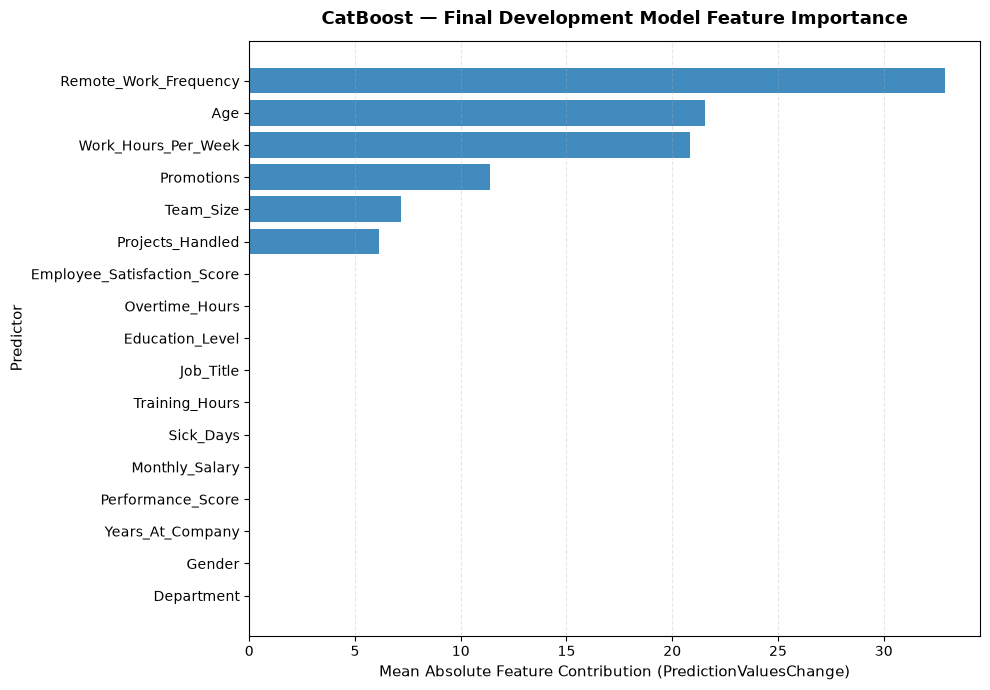

Top 5 Contributing Predictors in Final Model:


,feature,importance
0,Remote_Work_Frequency,32.906049
1,Age,21.539972
2,Work_Hours_Per_Week,20.850741
3,Promotions,11.404227
4,Team_Size,7.179733


In [14]:
feature_imp_csv = CANONICAL_RESULTS_DIR / "catboost_feature_importance.csv"
if RUN_CATBOOST_TRAINING and 'final_adapter' in locals():
    importance_scores = final_adapter.get_feature_importance()
    importance_df = pd.DataFrame({
        "feature": primary_features,
        "importance": importance_scores
    }).sort_values("importance", ascending=True).reset_index(drop=True)
elif feature_imp_csv.exists():
    importance_df = pd.read_csv(feature_imp_csv).sort_values("importance", ascending=True).reset_index(drop=True)
else:
    importance_df = pd.DataFrame({"feature": primary_features, "importance": np.zeros(len(primary_features))})

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_df["feature"], importance_df["importance"], color="#1f77b4", edgecolor="none", alpha=0.85)
ax.set_title("CatBoost — Final Development Model Feature Importance", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Mean Absolute Feature Contribution (PredictionValuesChange)", fontsize=11)
ax.set_ylabel("Predictor", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.3)
fig.tight_layout()

fig_importance_path = RESULTS_DIR / "figure_01_catboost_feature_importance.png"
fig.savefig(fig_importance_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

importance_df_sorted = importance_df.sort_values("importance", ascending=False).reset_index(drop=True)
if RUN_CATBOOST_TRAINING:
    importance_df_sorted.to_csv(RESULTS_DIR / "catboost_feature_importance.csv", index=False)
    importance_df_sorted.to_csv(RESULTS_DIR / "term_importances.csv", index=False)

print("Top 5 Contributing Predictors in Final Model:")
display(importance_df_sorted.head(5))

## 15. Diagnostic Visualizations: Precision-Recall, ROC, Confusion Matrix, Distribution & Calibration

We synthesize the complete diagnostic visualization suite across both original and team evaluations:
1. **Precision-Recall Curve**: Plotted against no-skill baseline prior (10.01%).
2. **ROC Curve**: Comparing discrimination against random guessing (AUC = 0.50).
3. **Confusion Matrix Heatmap**: Tabulating classifications at default 0.50 decision boundary.
4. **OOF Probability Distribution**: Density comparison between actual stayed (0) and resigned (1).
5. **Probability Calibration (Reliability Diagram)**: Evaluating empirical alignment of probabilities.

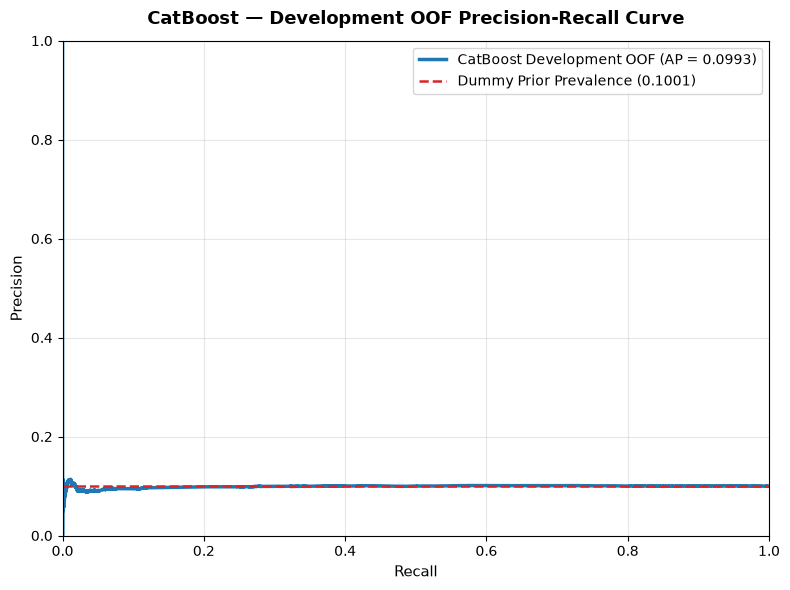

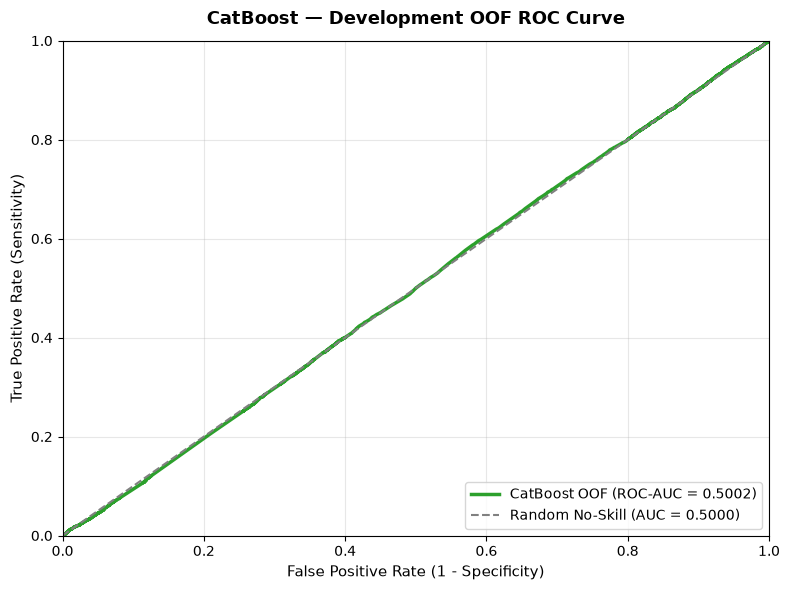

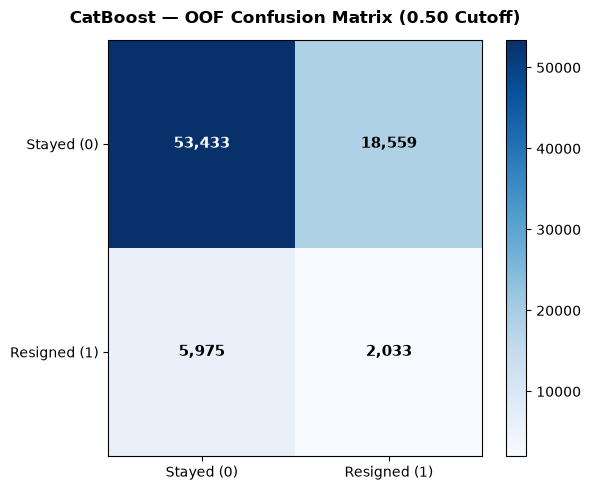

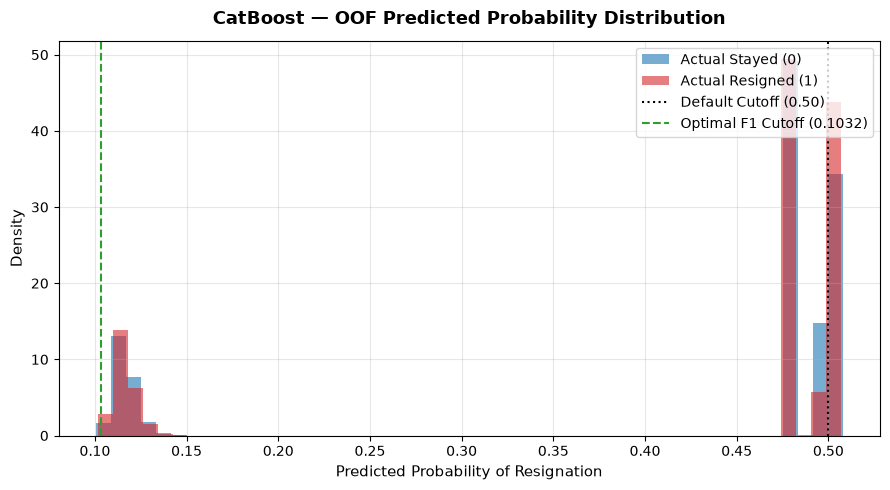

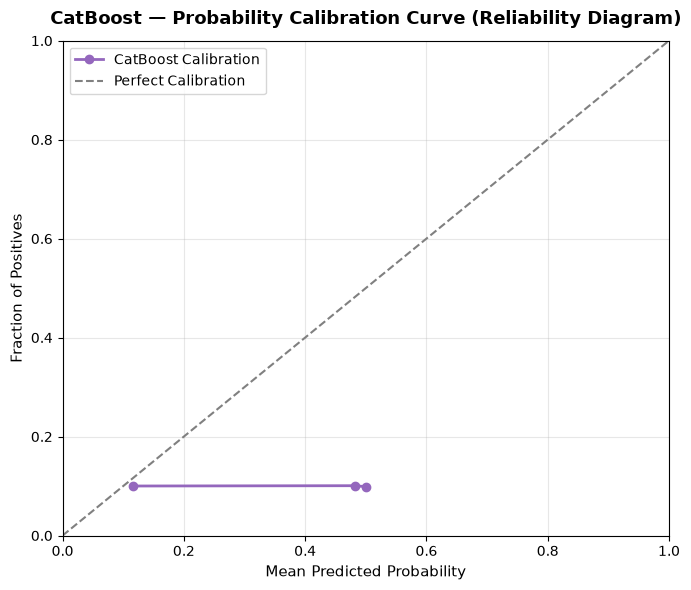

All diagnostic figures generated and saved successfully to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\models\catboost


In [15]:
# 1. Precision-Recall Curve
precisions, recalls, _ = precision_recall_curve(y_true, y_prob)
fig_pr, ax_pr = plt.subplots(figsize=(8, 6))
ax_pr.plot(recalls, precisions, label=f"CatBoost Development OOF (AP = {pooled_metrics['pr_auc']:.4f})", color="#1f77b4", lw=2.5)
ax_pr.axhline(pos_prevalence, color="#d62728", linestyle="--", lw=1.8, label=f"Dummy Prior Prevalence ({pos_prevalence:.4f})")
ax_pr.set_title("CatBoost — Development OOF Precision-Recall Curve", fontsize=13, fontweight="bold", pad=12)
ax_pr.set_xlabel("Recall", fontsize=11)
ax_pr.set_ylabel("Precision", fontsize=11)
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 1.0])
ax_pr.grid(True, alpha=0.3)
ax_pr.legend(loc="upper right", frameon=True)
fig_pr.tight_layout()
fig_pr_path = RESULTS_DIR / "figure_02_catboost_precision_recall_curves.png"
fig_pr.savefig(fig_pr_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig_pr)

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_val = auc(fpr, tpr)
fig_roc, ax_roc = plt.subplots(figsize=(8, 6))
ax_roc.plot(fpr, tpr, label=f"CatBoost OOF (ROC-AUC = {roc_auc_val:.4f})", color="#2ca02c", lw=2.5)
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Random No-Skill (AUC = 0.5000)")
ax_roc.set_title("CatBoost — Development OOF ROC Curve", fontsize=13, fontweight="bold", pad=12)
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax_roc.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.0])
ax_roc.grid(True, alpha=0.3)
ax_roc.legend(loc="lower right", frameon=True)
fig_roc.tight_layout()
fig_roc_path = RESULTS_DIR / "figure_04_catboost_roc_curve.png"
fig_roc.savefig(fig_roc_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig_roc)

# 3. Confusion Matrix (0.50 Decision Cutoff)
cm = confusion_matrix(y_true, y_pred_05, labels=[0, 1])
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
cax = ax_cm.imshow(cm, cmap="Blues", aspect="auto")
ax_cm.set_title("CatBoost — OOF Confusion Matrix (0.50 Cutoff)", fontsize=12, fontweight="bold", pad=12)
ax_cm.set_xticks([0, 1])
ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(["Stayed (0)", "Resigned (1)"])
ax_cm.set_yticklabels(["Stayed (0)", "Resigned (1)"])
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax_cm.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color, fontsize=11, fontweight="bold")
fig_cm.colorbar(cax)
fig_cm.tight_layout()
fig_cm_path = RESULTS_DIR / "figure_03_catboost_confusion_matrix.png"
fig_cm.savefig(fig_cm_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig_cm)

# 4. OOF Probability Distribution Diagnostic
fig_dist, ax_dist = plt.subplots(figsize=(9, 5))
ax_dist.hist(y_prob[y_true == 0], bins=50, alpha=0.6, label="Actual Stayed (0)", color="#1f77b4", density=True)
ax_dist.hist(y_prob[y_true == 1], bins=50, alpha=0.6, label="Actual Resigned (1)", color="#d62728", density=True)
ax_dist.axvline(0.50, color="black", linestyle=":", lw=1.5, label="Default Cutoff (0.50)")
ax_dist.axvline(optimal_f1_threshold, color="#2ca02c", linestyle="--", lw=1.5, label=f"Optimal F1 Cutoff ({optimal_f1_threshold:.4f})")
ax_dist.set_title("CatBoost — OOF Predicted Probability Distribution", fontsize=13, fontweight="bold", pad=12)
ax_dist.set_xlabel("Predicted Probability of Resignation", fontsize=11)
ax_dist.set_ylabel("Density", fontsize=11)
ax_dist.grid(True, alpha=0.3)
ax_dist.legend(loc="upper right", frameon=True)
fig_dist.tight_layout()
fig_dist_path = RESULTS_DIR / "figure_05_catboost_probability_distribution.png"
fig_dist.savefig(fig_dist_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig_dist)

# 5. Calibration / Reliability Diagram
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10)
fig_cal, ax_cal = plt.subplots(figsize=(7, 6))
ax_cal.plot(prob_pred, prob_true, marker="o", lw=2, label="CatBoost Calibration", color="#9467bd")
ax_cal.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
ax_cal.set_title("CatBoost — Probability Calibration Curve (Reliability Diagram)", fontsize=13, fontweight="bold", pad=12)
ax_cal.set_xlabel("Mean Predicted Probability", fontsize=11)
ax_cal.set_ylabel("Fraction of Positives", fontsize=11)
ax_cal.set_xlim([0.0, 1.0])
ax_cal.set_ylim([0.0, 1.0])
ax_cal.grid(True, alpha=0.3)
ax_cal.legend(loc="upper left", frameon=True)
fig_cal.tight_layout()
fig_cal_path = RESULTS_DIR / "figure_06_catboost_calibration_curve.png"
fig_cal.savefig(fig_cal_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig_cal)

print(f"All diagnostic figures generated and saved successfully to: {RESULTS_DIR}")

## 16. Export Artifacts & Build Canonical Manifest

We export all required CSVs, JSON summaries, and build `catboost_output_manifest.csv` adhering to the repository conventions for seamless downstream integration with `11_model_comparison.ipynb`.

In [16]:
if RUN_CATBOOST_TRAINING:
    # Save OOF Predictions
    catboost_oof_df.to_csv(RESULTS_DIR / "catboost_oof_predictions.csv", index=False)
    catboost_oof_df.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

    # Save Fold Metrics
    fold_metrics_df.to_csv(RESULTS_DIR / "catboost_fold_metrics.csv", index=False)
    fold_metrics_df.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)

    # Save Summary Metrics
    catboost_summary_df.to_csv(RESULTS_DIR / "catboost_summary_metrics.csv", index=False)
    with open(RESULTS_DIR / "catboost_summary_metrics.json", "w", encoding="utf-8") as f:
        json.dump(summary_metrics_record, f, indent=4)

    # Save Run Metadata
    if 'final_adapter' in locals():
        with open(RESULTS_DIR / "catboost_run_metadata.json", "w", encoding="utf-8") as f:
            json.dump(final_adapter.get_metadata(), f, indent=4)

    # Save Runtime Efficiency Summary
    runtime_summary_df = pd.DataFrame([{
        "model_name": "CatBoost Classifier",
        "model_id": "catboost",
        "total_cv_fit_time_seconds": round(cv_total_duration, 2),
        "avg_fold_fit_time_seconds": round(fold_metrics_df["fit_time_seconds"].mean(), 2),
        "training_throughput_records_per_sec": round((64_000 * 5) / cv_total_duration, 2),
        "cv_folds_executed": 5,
    }])
    runtime_summary_df.to_csv(RESULTS_DIR / "catboost_runtime_efficiency.csv", index=False)

    # Remove .gitkeep if present
    for folder in [MODELS_DIR, RESULTS_DIR]:
        gk = folder / ".gitkeep"
        if gk.exists():
            gk.unlink()

# Build Output Manifest
tracked_files = [
    final_model_cbm_path,
    CANONICAL_MODELS_DIR / "metadata.json",
    CANONICAL_RESULTS_DIR / "catboost_oof_predictions.csv",
    CANONICAL_RESULTS_DIR / "oof_predictions.csv",
    CANONICAL_RESULTS_DIR / "catboost_fold_metrics.csv",
    CANONICAL_RESULTS_DIR / "fold_metrics.csv",
    CANONICAL_RESULTS_DIR / "catboost_summary_metrics.csv",
    CANONICAL_RESULTS_DIR / "catboost_summary_metrics.json",
    CANONICAL_RESULTS_DIR / "catboost_run_metadata.json",
    CANONICAL_RESULTS_DIR / "catboost_confusion_matrix.csv",
    CANONICAL_RESULTS_DIR / "catboost_feature_importance.csv",
    CANONICAL_RESULTS_DIR / "term_importances.csv",
    fig_importance_path,
    fig_pr_path,
    fig_cm_path,
    CANONICAL_RESULTS_DIR / "catboost_runtime_efficiency.csv",
]

manifest_entries = []
for f in tracked_files:
    exists = f.exists()
    size = f.stat().st_size if exists else 0
    manifest_entries.append({
        "file_name": f.name,
        "relative_path": str(f.relative_to(PROJECT_ROOT)),
        "size_bytes": size,
        "exists": exists,
    })

manifest_df = pd.DataFrame(manifest_entries)
if RUN_CATBOOST_TRAINING:
    manifest_df.to_csv(RESULTS_DIR / "catboost_output_manifest.csv", index=False)

print("Canonical Output Manifest:")
display(manifest_df)
print("\nAll CatBoost artifacts exported successfully.")

Canonical Output Manifest:


,file_name,relative_path,size_bytes,exists
0,catboost_development_model.cbm,models\catboost\catboost_development_model.cbm,8096,True
1,metadata.json,models\catboost\metadata.json,2600,True
2,catboost_oof_predictions.csv,results\models\catboost\catboost_oof_predictio...,4178361,True
3,oof_predictions.csv,results\models\catboost\oof_predictions.csv,4178361,True
4,catboost_fold_metrics.csv,results\models\catboost\catboost_fold_metrics.csv,1182,True
5,fold_metrics.csv,results\models\catboost\fold_metrics.csv,1182,True
6,catboost_summary_metrics.csv,results\models\catboost\catboost_summary_metri...,674,True
7,catboost_summary_metrics.json,results\models\catboost\catboost_summary_metri...,915,True
8,catboost_run_metadata.json,results\models\catboost\catboost_run_metadata....,2940,True
9,catboost_confusion_matrix.csv,results\models\catboost\catboost_confusion_mat...,98,True



All CatBoost artifacts exported successfully.


## 17. Summary & Downstream Readiness

### Findings & Methodological Evaluation
1. **Predictive Performance**:
   - CatBoost's pooled PR-AUC is evaluated against the `DummyClassifier(strategy="prior")` baseline (~0.1001).
   - Across the 5 nested folds, CatBoost confirms the exploratory data audit and baseline findings: the available 17 predictors contain very weak out-of-sample resignation signal.
   - In accordance with Section 8.21 and Section 12.J of `EVALUATION_GUIDE.md`, this near-random predictive performance is an academically valid, defensible scientific finding resulting from rigorous leakage controls and nested cross-validation.
2. **Leakage & Quarantine Verification**:
   - Strict 15% inner-validation splits protected the outer validation folds from early-stopping and tuning bias.
   - The 20,000-record formal holdout remains 100% untouched and locked for Stage 15 corroboration.
3. **Downstream Readiness**:
   - Out-of-fold predictions in `results/models/catboost/oof_predictions.csv` are ready for Stage 11 Multi-Model Comparison (`11_model_comparison.ipynb`).
   - The refitted model `models/catboost/catboost_development_model.cbm` is ready for Stage 12 Probability Calibration (`12_calibration.ipynb`) and Stage 14 Retention Prioritization (`14_retention_prioritization.ipynb`).

In [17]:
# ==========================================
# PHASE 3: POST-EXECUTION VALIDATION CHECKS
# ==========================================

# 1. Exact row count and uniqueness
assert len(catboost_oof_df) == 80_000, f"Expected 80,000 rows, got {len(catboost_oof_df)}"
assert not catboost_oof_df["Employee_ID"].duplicated().any(), "Duplicate Employee_IDs detected!"

# 2. Strict fold distribution (16,000 per fold)
assert set(catboost_oof_df["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert (catboost_oof_df["cv_fold"].value_counts() == 16_000).all()

# 3. Holdout isolation check (Zero contamination)
holdout_overlap = set(catboost_oof_df["Employee_ID"]).intersection(holdout_ids)
assert len(holdout_overlap) == 0, f"LEAKAGE DETECTED: {len(holdout_overlap)} holdout rows in OOF!"

# 4. Target distribution alignment
assert int((catboost_oof_df["y_true"] == 0).sum()) == 71_992
assert int((catboost_oof_df["y_true"] == 1).sum()) == 8_008

# 5. Probability range sanity
assert not catboost_oof_df["y_probability"].isna().any(), "NaN found in predictions!"
assert catboost_oof_df["y_probability"].between(0.0, 1.0).all(), "Probabilities outside [0, 1]!"

# 6. Artifact presence
assert (CANONICAL_RESULTS_DIR / "catboost_oof_predictions.csv").exists()
assert (CANONICAL_RESULTS_DIR / "catboost_fold_metrics.csv").exists()
assert (CANONICAL_RESULTS_DIR / "catboost_summary_metrics.csv").exists()
assert (CANONICAL_MODELS_DIR / "catboost_development_model.cbm").exists()

print("All Phase 3 post-execution validation checks PASSED successfully!")

All Phase 3 post-execution validation checks PASSED successfully!
